# Статистический анализ сетевого трафика UNSW-NB15

Исследуются распределения характеристик сетевых соединений, их статистическая связь с наличием атаки, взаимные корреляции и качество бинарной классификации.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
DATA_DIR = Path(".")  # Папка с UNSW_NB15_training-set.csv и UNSW_NB15_testing-set.csv
OUT = Path("unsw_results")
OUT.mkdir(exist_ok=True)
ALPHA = 0.05
RANDOM_STATE = 42


## 1. Загрузка и проверка данных

Загрузка обучающей и тестовой выборок, контроль структуры, пропусков, меток и повторяющихся наблюдений.

In [2]:
# Поддерживаются как исходные имена CSV, так и имена приложенных файлов с суффиксом (1).
def csv_path(stem):
    variants = [DATA_DIR / (stem + ".csv"), DATA_DIR / (stem + "(1).csv")]
    for filename in variants:
        if filename.is_file():
            return filename
    raise FileNotFoundError(f"Файл {stem}.csv не найден в {DATA_DIR.resolve()}")

train = pd.read_csv(csv_path("UNSW_NB15_training-set"), low_memory=False)
test = pd.read_csv(csv_path("UNSW_NB15_testing-set"), low_memory=False)
print(f"Train: {train.shape}; Test: {test.shape}")
display(train.head(3))

Train: (175341, 45); Test: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0


In [3]:
# Одна ячейка для проверки структуры и качества обоих исходных файлов.
expected_cols = set(train.columns)
assert train.columns.tolist() == test.columns.tolist(), "Состав/порядок столбцов отличается"
assert train.dtypes.equals(test.dtypes), "Типы столбцов различаются"
assert {"id", "label", "attack_cat"}.issubset(expected_cols), "Нет обязательных полей"

nonnegative = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "sload", "dload"]
rows = []
for name, df in [("train", train), ("test", test)]:
    numeric = df.select_dtypes(include="number")
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    blanks = sum(int(df[c].eq("").sum()) for c in text_cols)
    whitespace = sum(int(df[c].ne(df[c].str.strip()).sum()) for c in text_cols)
    inconsistent = int(((df["label"] == 0) != (df["attack_cat"] == "Normal")).sum())
    rows.append({
        "dataset": name, "rows": len(df), "columns": df.shape[1],
        "missing": int(df.isna().sum().sum()),
        "infinite": int(np.isinf(numeric.to_numpy(dtype=float)).sum()),
        "blank_strings": blanks, "extra_spaces": whitespace,
        "invalid_labels": int((~df["label"].isin([0, 1])).sum()),
        "label_attack_cat_mismatch": inconsistent,
        "negative_expected_nonnegative": int((df[nonnegative] < 0).sum().sum()),
        "duplicates_without_id": int(df.drop(columns="id").duplicated().sum()),
    })
quality = pd.DataFrame(rows).set_index("dataset")
display(quality)
assert (quality[["missing", "infinite", "blank_strings", "extra_spaces", "invalid_labels", "label_attack_cat_mismatch", "negative_expected_nonnegative"]] == 0).all().all(), "Обнаружена проблема качества данных — изучите таблицу"
print("Проверки пройдены. Очистка не нужна. Повторяющиеся записи не удаляются.")

,rows,columns,missing,infinite,blank_strings,extra_spaces,invalid_labels,label_attack_cat_mismatch,negative_expected_nonnegative,duplicates_without_id
dataset,,,,,,,,,,
train,175341,45,0,0,0,0,0,0,0,67601
test,82332,45,0,0,0,0,0,0,0,26387


Проверки пройдены. Очистка не нужна. Повторяющиеся записи не удаляются.


## 2. Описательная статистика и информативность признаков

Распределения классов, описательные статистики и ранжирование всех 42 признаков по ROC-AUC одномерных моделей.

,Число,"Доля, %"
Класс,,
Атака,119341,68.06
Норма,56000,31.94


,Число,"Доля, %"
Категория,,
Normal,56000,31.94
Generic,40000,22.81
Exploits,33393,19.04
Fuzzers,18184,10.37
DoS,12264,6.99
Reconnaissance,10491,5.98
Analysis,2000,1.14
Backdoor,1746,1.00
Shellcode,1133,0.65


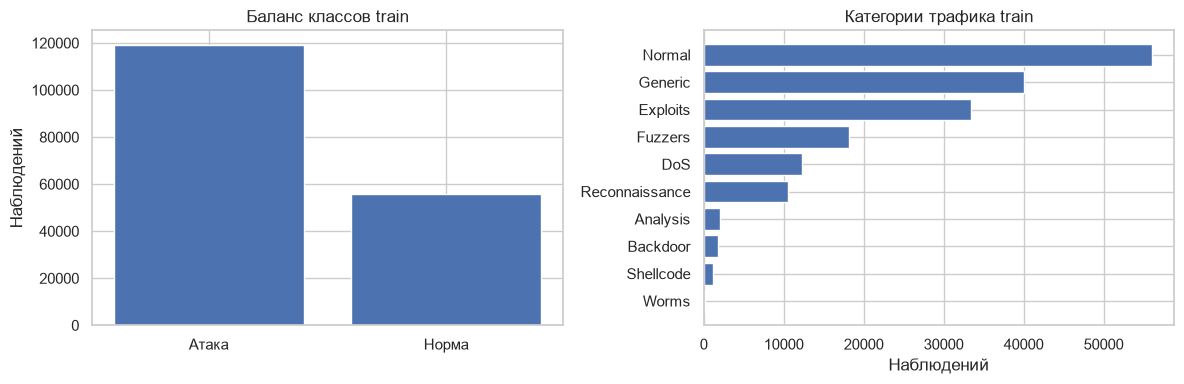

In [4]:
# Распределение меток и видов атак — отправная точка для интерпретации информативности.
class_table = train["label"].map({0: "Норма", 1: "Атака"}).value_counts().rename_axis("Класс").to_frame("Число")
class_table["Доля, %"] = (100 * class_table["Число"] / len(train)).round(2)
attack_table = train["attack_cat"].value_counts().rename_axis("Категория").to_frame("Число")
attack_table["Доля, %"] = (100 * attack_table["Число"] / len(train)).round(2)
display(class_table, attack_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(class_table.index, class_table["Число"])
axes[0].set(title="Баланс классов train", ylabel="Наблюдений")
axes[1].barh(attack_table.index, attack_table["Число"])
axes[1].invert_yaxis()
axes[1].set(title="Категории трафика train", xlabel="Наблюдений")
plt.tight_layout()
plt.show()

### 2.1. Одномерные модели

Обучающая выборка разбивается на подвыборку построения (75%) и проверочную (25%). На первой определяются интервалы значений и сглаженные доли атак, на второй вычисляется ROC-AUC. Тестовая выборка не используется.

Проверено: 39 числовых и 3 категориальных признака
Внутренняя оценка: fit=131505, validation=43836, доля атак validation=68.06%
ТОП-20 признаков по одномерному ROC-AUC (только внутренняя validation из train):


,rank,feature,type,n_unique_train,encoding,n_groups,auc_validation,auc_gain_over_random
0,1,ct_state_ttl,numeric,5,дискретные значения,5,0.9012,0.4012
1,2,dttl,numeric,6,дискретные значения,6,0.8895,0.3895
2,3,sttl,numeric,11,дискретные значения,11,0.8867,0.3867
3,4,dinpkt,numeric,56579,отдельный ноль + квантили положительных,11,0.8762,0.3762
4,5,dload,numeric,59147,отдельный ноль + квантили положительных,11,0.8709,0.3709
5,6,dur,numeric,57107,квантильные интервалы,9,0.8547,0.3547
6,7,dpkts,numeric,398,отдельный ноль + квантили положительных,10,0.8539,0.3539
7,8,smean,numeric,1338,квантильные интервалы,9,0.8420,0.3420
8,9,dmean,numeric,1290,отдельный ноль + квантили положительных,11,0.8416,0.3416
9,10,sbytes,numeric,5993,квантильные интервалы,9,0.8388,0.3388


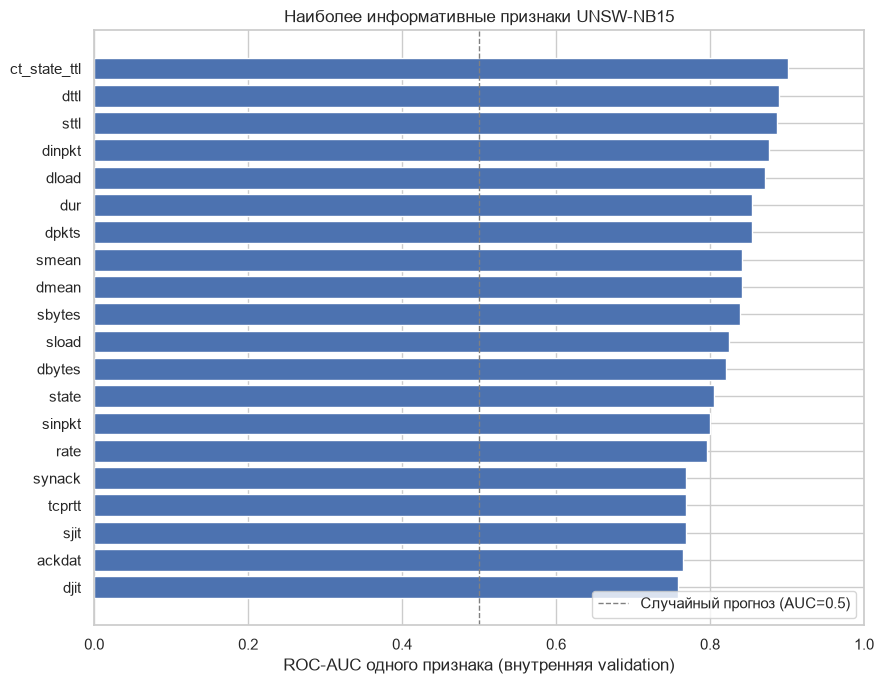

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Важный принцип: ни один результат этого раздела не использует официальный test.
excluded = {"id", "label", "attack_cat"}
input_features = [c for c in train.columns if c not in excluded]
numeric_features = [c for c in input_features if pd.api.types.is_numeric_dtype(train[c])]
categorical_features = [c for c in input_features if c not in numeric_features]
assert len(input_features) == 42 and len(categorical_features) == 3

fit_idx, valid_idx = train_test_split(
    np.arange(len(train)), test_size=0.25, stratify=train["label"], random_state=RANDOM_STATE
)
fit_part = train.iloc[fit_idx]
valid_part = train.iloc[valid_idx]
y_fit = fit_part["label"].to_numpy(dtype=int)
y_valid = valid_part["label"].to_numpy(dtype=int)
base_rate = float(y_fit.mean())

SMOOTHING = 30.0
MAX_LEVELS = 20
N_QUANTILES = 10
MIN_CATEGORY_COUNT = 30
ranking_rows = []
profile_rows = []
validation_score_by_feature = {}  # Замороженные оценки, построенные исключительно на fit

for feature in input_features:
    is_num = feature in numeric_features
    fit_values, valid_values = fit_part[feature], valid_part[feature]
    unique_values = fit_values.nunique(dropna=False)

    if is_num and unique_values > MAX_LEVELS:
        fit_numeric = fit_values.to_numpy(dtype=float)
        valid_numeric = valid_values.to_numpy(dtype=float)
        zero_spike = (np.mean(fit_numeric == 0) >= 0.25 and
                      (fit_numeric > 0).sum() >= MIN_CATEGORY_COUNT and
                      np.min(fit_numeric) >= 0)
        if zero_spike:
            # Большая атомарная масса в нуле: общие квантили иногда дают
            # только один интервал и полностью теряют различие 0 / >0.
            # Поэтому ноль выделяем в отдельную группу, а ненулевые значения
            # разбиваем по квантилям, рассчитанным ТОЛЬКО на fit_part.
            positive_fit = fit_numeric[fit_numeric > 0]
            positive_edges = np.unique(np.quantile(positive_fit, np.linspace(0, 1, N_QUANTILES + 1)))
            cutoffs = positive_edges[1:-1]
            fit_bins = np.where(fit_numeric == 0, 0,
                                1 + np.searchsorted(cutoffs, fit_numeric, side="left"))
            valid_bins = np.where(valid_numeric == 0, 0,
                                  1 + np.searchsorted(cutoffs, valid_numeric, side="left"))
            bin_names = {0: "Ровно 0"}
            for i in range(1, len(cutoffs) + 2):
                if len(cutoffs) == 0:
                    label = "(0; +∞)"
                elif i == 1:
                    label = f"(0; {cutoffs[0]:.4g}]"
                elif i == len(cutoffs) + 1:
                    label = f"({cutoffs[-1]:.4g}; +∞)"
                else:
                    label = f"({cutoffs[i - 2]:.4g}; {cutoffs[i - 1]:.4g}]"
                bin_names[i] = label
            encoding = "отдельный ноль + квантили положительных"
        else:
            # Обычные квантили, без использования validation и test.
            edges = np.unique(np.quantile(fit_numeric, np.linspace(0, 1, N_QUANTILES + 1)))
            cutoffs = edges[1:-1]
            fit_bins = np.searchsorted(cutoffs, fit_numeric, side="left")
            valid_bins = np.searchsorted(cutoffs, valid_numeric, side="left")
            bin_names = {
                i: (f"(-∞; {cutoffs[0]:.4g}]" if i == 0 else
                    f"({cutoffs[-1]:.4g}; +∞)" if i == len(cutoffs) else
                    f"({cutoffs[i - 1]:.4g}; {cutoffs[i]:.4g}]")
                for i in range(len(cutoffs) + 1)
            } if len(cutoffs) else {0: "Все значения"}
            encoding = "квантильные интервалы"
    else:
        # Низкая кардинальность: не теряем индикаторы и дискретные значения.
        if is_num:
            fit_bins = fit_values.astype(str).to_numpy()
            valid_bins = valid_values.astype(str).to_numpy()
            encoding = "дискретные значения"
        else:
            counts = fit_values.value_counts(dropna=False)
            kept = set(counts[counts >= MIN_CATEGORY_COUNT].index)
            fit_bins = np.where(fit_values.isin(kept), fit_values.astype(str), "__RARE__")
            valid_bins = np.where(valid_values.isin(kept), valid_values.astype(str), "__RARE__")
            encoding = "категории (редкие объединены)"
        bin_names = None

    train_counts = pd.DataFrame({"bucket": fit_bins, "attack": y_fit}).groupby("bucket")["attack"].agg(["size", "sum"])
    risks = (train_counts["sum"] + SMOOTHING * base_rate) / (train_counts["size"] + SMOOTHING)
    validation_score = pd.Series(valid_bins).map(risks).fillna(base_rate).to_numpy(dtype=float)
    validation_score_by_feature[feature] = validation_score
    auc = roc_auc_score(y_valid, validation_score)
    ranking_rows.append({
        "feature": feature, "type": "numeric" if is_num else "categorical",
        "n_unique_train": int(unique_values), "encoding": encoding,
        "n_groups": int(len(train_counts)), "auc_validation": float(auc),
        "auc_gain_over_random": float(auc - 0.5),
    })

    # Профили групп рассчитываются на validation. Числа не используются при построении score.
    p = pd.DataFrame({"bucket": valid_bins, "attack": y_valid}).groupby("bucket", sort=True)["attack"].agg(["size", "sum"])
    for bucket, row in p.iterrows():
        profile_rows.append({
            "feature": feature, "bucket": str(bin_names.get(bucket, bucket) if bin_names else bucket),
            "n_validation": int(row["size"]), "attacks_validation": int(row["sum"]),
            "attack_share_validation": float(row["sum"] / row["size"]),
            "predicted_attack_share_fit": float(risks.get(bucket, base_rate)),
            "bin_order": int(bucket) if bin_names else np.nan,
        })

feature_informativeness = pd.DataFrame(ranking_rows).sort_values("auc_validation", ascending=False).reset_index(drop=True)
feature_informativeness.insert(0, "rank", np.arange(1, len(feature_informativeness) + 1))
feature_bin_profiles = pd.DataFrame(profile_rows)
print(f"Проверено: {len(numeric_features)} числовых и {len(categorical_features)} категориальных признака")
print(f"Внутренняя оценка: fit={len(fit_part)}, validation={len(valid_part)}, доля атак validation={y_valid.mean():.2%}")
print("ТОП-20 признаков по одномерному ROC-AUC (только внутренняя validation из train):")
display(feature_informativeness.head(20).round(4))

fig, ax = plt.subplots(figsize=(9, 7))
top = feature_informativeness.head(20).iloc[::-1]
ax.barh(top["feature"], top["auc_validation"])
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="Случайный прогноз (AUC=0.5)")
ax.set(xlim=(0, 1), xlabel="ROC-AUC одного признака (внутренняя validation)", title="Наиболее информативные признаки UNSW-NB15")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUT / "feature_informativeness_ranking.png", dpi=150, bbox_inches="tight")
plt.show()


### 2.2. Распределения наиболее информативных признаков

Описательные статистики по классам, профили числовых признаков, частоты категорий и диагностика выбросов.

In [6]:
# Сохраняем исходные таблицы описательной статистики для дальнейшего экспорта.
def describe(df):
    grouped = df[numeric_features].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T
    grouped["q25"] = df[numeric_features].quantile(0.25)
    grouped["q75"] = df[numeric_features].quantile(0.75)
    grouped["excess_kurtosis"] = df[numeric_features].kurt()
    return grouped

stats_all = describe(train)
stats_by_class = pd.concat({
    "Норма": describe(train.loc[train.label == 0]),
    "Атака": describe(train.loc[train.label == 1])
}, names=["class", "feature"])
means = train.groupby("label")[numeric_features].mean()
medians = train.groupby("label")[numeric_features].median()
comparison = pd.DataFrame({
    "mean_normal": means.loc[0], "mean_attack": means.loc[1],
    "median_normal": medians.loc[0], "median_attack": medians.loc[1],
})
comparison["delta_mean"] = comparison.mean_attack - comparison.mean_normal
comparison["delta_median"] = comparison.median_attack - comparison.median_normal
comparison["zero_pct_normal"] = 100 * train.loc[train.label == 0, numeric_features].eq(0).mean()
comparison["zero_pct_attack"] = 100 * train.loc[train.label == 1, numeric_features].eq(0).mean()

# Показываем в первую очередь признаки, которые признаны информативными в предыдущей ячейке.
top_numeric = feature_informativeness.loc[feature_informativeness.type == "numeric", "feature"].head(12).tolist()
print("Описательные статистики для 12 наиболее информативных количественных признаков:")
display(comparison.loc[top_numeric].round(3))
print("Полные описательные статистики всех числовых признаков доступны в переменных stats_all, stats_by_class.")


Описательные статистики для 12 наиболее информативных количественных признаков:


,mean_normal,mean_attack,median_normal,median_attack,delta_mean,delta_median,zero_pct_normal,zero_pct_attack
ct_state_ttl,4.990000e-01,1.682000e+00,0.000,2.0,1.183000e+00,2.000000e+00,71.262,0.741
dttl,6.427600e+01,8.680500e+01,29.000,0.0,2.252800e+01,-2.900000e+01,12.046,65.046
sttl,7.544600e+01,2.283960e+02,31.000,254.0,1.529500e+02,2.230000e+02,5.105,0.254
dinpkt,1.211970e+02,7.274000e+01,0.911,0.0,-4.845600e+01,-9.110000e-01,11.905,65.046
dload,2.062949e+06,1.813877e+04,336120.641,0.0,-2.044810e+06,-3.361206e+05,11.900,65.046
dur,1.017000e+00,1.520000e+00,0.039,0.0,5.030000e-01,-3.900000e-02,4.696,0.023
dpkts,3.805800e+01,1.001300e+01,10.000,0.0,-2.804500e+01,-1.000000e+01,11.886,65.046
smean,1.399780e+02,1.352380e+02,73.000,76.0,-4.740000e+00,3.000000e+00,0.000,0.000
dmean,2.530670e+02,6.369100e+01,89.000,0.0,-1.893770e+02,-8.900000e+01,11.886,65.046
sbytes,4.105703e+03,1.106866e+04,1470.000,200.0,6.962952e+03,-1.270000e+03,0.000,0.000


Полные описательные статистики всех числовых признаков доступны в переменных stats_all, stats_by_class.


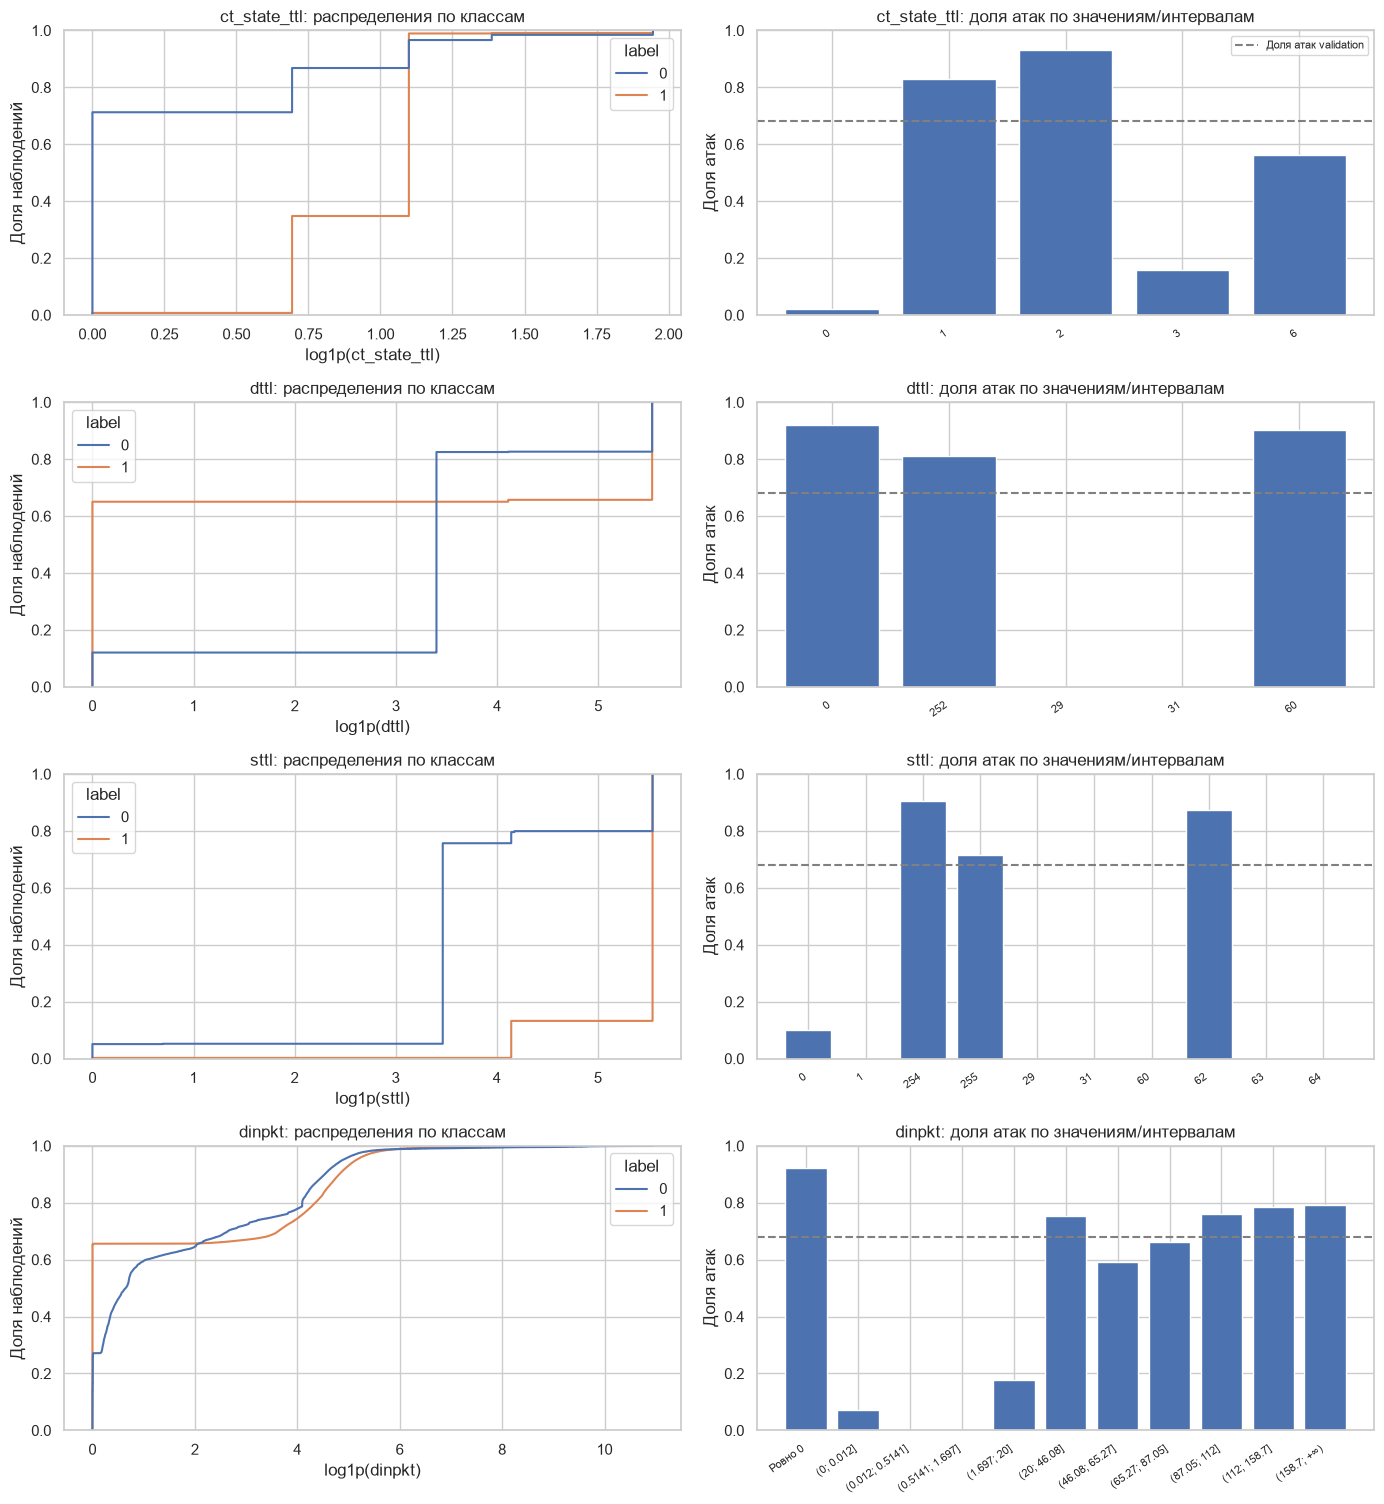

In [7]:
# Графики: распределение и риск атаки для 4 наиболее информативных числовых характеристик.
# Используем всю train для распределений по классам; validation — для оценки риска по группам.
most_informative_numeric = top_numeric[:4]
fig, axes = plt.subplots(len(most_informative_numeric), 2, figsize=(14, 3.8 * len(most_informative_numeric)))
for i, feature in enumerate(most_informative_numeric):
    data = train[[feature, "label"]].copy()
    # Для неотрицательных переменных логарифм меняет только масштаб рисунка, не исходные значения.
    log_scale = bool(data[feature].ge(0).all())
    data["shown"] = np.log1p(data[feature]) if log_scale else data[feature]
    sns.ecdfplot(data=data, x="shown", hue="label", hue_order=[0, 1], ax=axes[i, 0])
    axes[i, 0].set(xlabel=f"log1p({feature})" if log_scale else feature,
                    ylabel="Доля наблюдений", title=f"{feature}: распределения по классам")
    prof = feature_bin_profiles.loc[feature_bin_profiles.feature == feature].copy()
    prof = prof.sort_values("bin_order" if prof.bin_order.notna().any() else "bucket")
    axes[i, 1].bar(np.arange(len(prof)), prof["attack_share_validation"])
    axes[i, 1].axhline(y_valid.mean(), color="gray", ls="--", label="Доля атак validation")
    axes[i, 1].set(ylim=(0, 1), ylabel="Доля атак", title=f"{feature}: доля атак по значениям/интервалам")
    axes[i, 1].set_xticks(np.arange(len(prof)))
    axes[i, 1].set_xticklabels(prof["bucket"], rotation=35, ha="right", fontsize=8)
    if i == 0: axes[i, 1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "informative_numeric_profiles.png", dpi=150, bbox_inches="tight")
plt.show()


proto: 8 наиболее частых категорий (доля атак внутри категории):


,feature,category,n,attacks,attack_share
0,proto,tcp,79946,40825,0.5107
1,proto,udp,63283,49361,0.7800
2,proto,unas,12084,12084,1.0000
3,proto,arp,2859,0,0.0000
4,proto,ospf,2595,2531,0.9753
5,proto,sctp,1150,1150,1.0000
6,proto,any,300,300,1.0000
7,proto,gre,225,225,1.0000


service: 8 наиболее частых категорий (доля атак внутри категории):


,feature,category,n,attacks,attack_share
133,service,-,94168,57656,0.6123
134,service,dns,47294,39801,0.8416
135,service,http,18724,13376,0.7144
136,service,smtp,5058,3479,0.6878
137,service,ftp-data,3995,1443,0.3612
138,service,ftp,3428,2210,0.6447
139,service,ssh,1302,11,0.0084
140,service,pop3,1105,1101,0.9964


state: 8 наиболее частых категорий (доля атак внутри категории):


,feature,category,n,attacks,attack_share
146,state,INT,82275,76560,0.9305
147,state,FIN,77825,40650,0.5223
148,state,CON,13152,1053,0.0801
149,state,REQ,1991,1066,0.5354
150,state,RST,83,12,0.1446
151,state,ECO,12,0,0.0000
152,state,PAR,1,0,0.0000
153,state,URN,1,0,0.0000


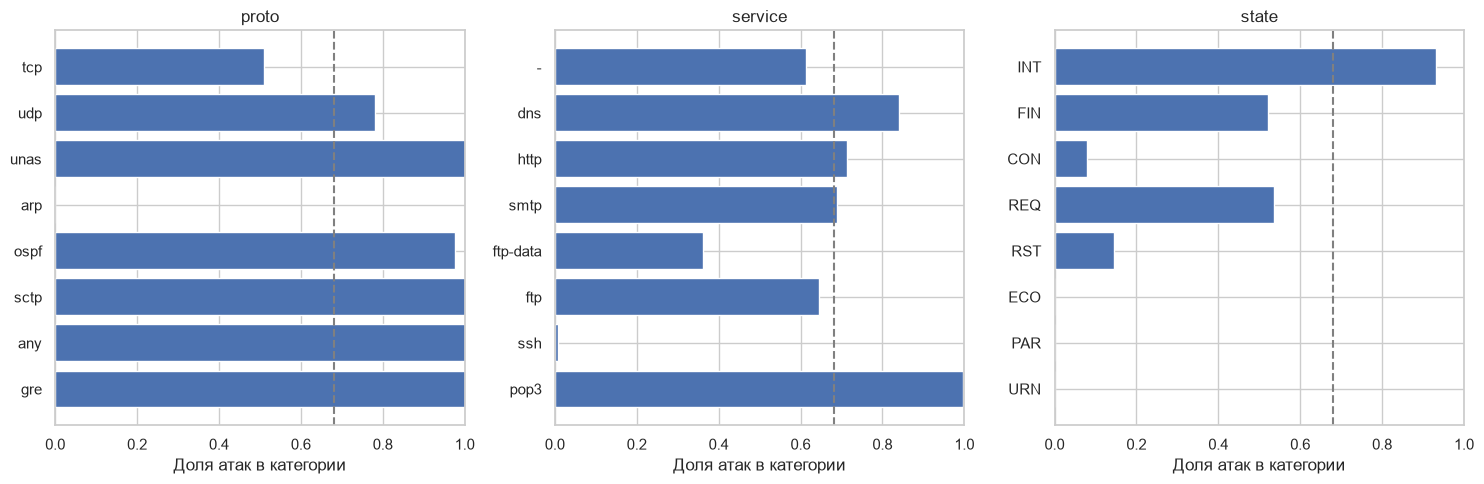

In [8]:
# Интерпретация категориальных характеристик: частоты и условные доли атак.
# Сортировка по числу наблюдений, а не по доле атак, чтобы не переоценивать редкие категории.
category_rows = []
for feature in categorical_features:
    grouped = train.groupby(feature)["label"].agg(n="size", attacks="sum").sort_values("n", ascending=False)
    grouped["attack_share"] = grouped["attacks"] / grouped["n"]
    for category, row in grouped.iterrows():
        category_rows.append({"feature": feature, "category": category,
                              "n": int(row["n"]), "attacks": int(row["attacks"]),
                              "attack_share": float(row["attack_share"])})
categorical_attack_rates = pd.DataFrame(category_rows)
for feature in categorical_features:
    top_categories = categorical_attack_rates.loc[categorical_attack_rates.feature == feature].head(8)
    print(f"{feature}: 8 наиболее частых категорий (доля атак внутри категории):")
    display(top_categories.round(4))

fig, axes = plt.subplots(1, len(categorical_features), figsize=(15, 5))
for ax, feature in zip(axes, categorical_features):
    tmp = categorical_attack_rates.loc[categorical_attack_rates.feature == feature].head(8).iloc[::-1]
    ax.barh(tmp["category"].astype(str), tmp["attack_share"])
    ax.axvline(train.label.mean(), color="gray", ls="--")
    ax.set(xlim=(0, 1), title=feature, xlabel="Доля атак в категории")
plt.tight_layout()
plt.savefig(OUT / "informative_categorical_profiles.png", dpi=150, bbox_inches="tight")
plt.show()


In [9]:
# Проверка хвостов распределений: IQR используется только для диагностики, а не для удаления строк.
# Особенно осторожно трактуем результат при IQR=0 (характерно для дискретных переменных).
q1, q3 = train[numeric_features].quantile(0.25), train[numeric_features].quantile(0.75)
iqr = q3 - q1
flags = train[numeric_features].lt(q1 - 1.5 * iqr) | train[numeric_features].gt(q3 + 1.5 * iqr)
outlier_table = pd.DataFrame({
    "IQR": iqr, "IQR_zero": iqr.eq(0),
    "outside_IQR_pct": 100 * flags.mean(),
    "outside_IQR_normal_pct": 100 * flags.loc[train.label == 0].mean(),
    "outside_IQR_attack_pct": 100 * flags.loc[train.label == 1].mean(),
})
print("IQR-диагностика только для наиболее информативных числовых переменных (данные не удаляются):")
display(outlier_table.loc[top_numeric[:10]].round(2))


IQR-диагностика только для наиболее информативных числовых переменных (данные не удаляются):


,IQR,IQR_zero,outside_IQR_pct,outside_IQR_normal_pct,outside_IQR_attack_pct
ct_state_ttl,1.00,False,1.10,1.54,0.89
dttl,252.00,False,0.00,0.00,0.00
sttl,192.00,False,0.00,0.00,0.00
dinpkt,51.05,False,8.04,5.29,9.33
dload,27844.87,False,21.75,60.32,3.66
dur,0.67,False,8.98,6.71,10.04
dpkts,10.00,False,11.88,28.72,3.98
smean,43.00,False,11.82,13.11,11.22
dmean,89.00,False,13.32,28.94,5.99
sbytes,1304.00,False,13.04,25.01,7.43


## 3. Статистические гипотезы

Проверяется связь одномерных прогнозов всех 42 признаков с меткой атаки. Для каждого фиксированного прогноза выполняется 999 перестановок проверочных меток; рассчитываются ROC-AUC, перестановочные p-значения и поправки Холма и Бенджамини—Хохберга.

In [10]:
# Проверяем все 42 заранее определённые гипотезы на внутренней validation.
# Скоринги обучены на fit_part, а validation до этого использована только для
# ОЦЕНКИ качества и отображения ранжирования (но НЕ для подгонки скорингов).
# Поскольку тестируем ВСЕ 42 признака, не выбираем постфактум отдельные гипотезы.
from scipy.stats import rankdata

N_PERMUTATIONS = 999
rng_perm = np.random.default_rng(RANDOM_STATE + 2026)
feature_order = list(input_features)
n_confirm = len(y_valid)
n_pos = int(y_valid.sum())
n_neg = int(n_confirm - n_pos)
assert n_pos > 0 and n_neg > 0

# Ранги учитывают точные совпадения предсказанных значений: average-rank ties.
score_rank_matrix = np.column_stack([
    rankdata(validation_score_by_feature[f], method="average")
    for f in feature_order
]).astype(np.float32)

# Эквивалент обычной ROC-AUC: U Манна–Уитни / (n_pos * n_neg).
rank_sum_pos = score_rank_matrix[y_valid == 1].sum(axis=0, dtype=np.float64)
auc_from_ranks = (rank_sum_pos - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
auc_from_sklearn = np.array([roc_auc_score(y_valid, validation_score_by_feature[f]) for f in feature_order])
assert np.allclose(auc_from_ranks, auc_from_sklearn, atol=3e-6)

# Перестановка меток делается в небольших батчах, чтобы экономить память.
# Для каждой перестановки AUC всех 42 фиксированных скорингов считается одним матричным произведением.
null_ge_observed = np.zeros(len(feature_order), dtype=np.int64)
PERM_BATCH_SIZE = 40
for start in range(0, N_PERMUTATIONS, PERM_BATCH_SIZE):
    batch_size = min(PERM_BATCH_SIZE, N_PERMUTATIONS - start)
    permutation_matrix = np.empty((batch_size, n_confirm), dtype=np.float32)
    for b in range(batch_size):
        permutation_matrix[b, :] = rng_perm.permutation(y_valid)
    perm_rank_sums = permutation_matrix @ score_rank_matrix
    perm_auc = (perm_rank_sums.astype(np.float64) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
    null_ge_observed += (perm_auc >= (auc_from_ranks[None, :] - 2e-6)).sum(axis=0)

p_perm = (null_ge_observed + 1) / (N_PERMUTATIONS + 1)
reject_bh, q_bh, _, _ = multipletests(p_perm, alpha=ALPHA, method="fdr_bh")
reject_holm, p_holm, _, _ = multipletests(p_perm, alpha=ALPHA, method="holm")

results = pd.DataFrame({
    "feature": feature_order,
    "auc_validation": auc_from_sklearn,
    "auc_gain_over_random": auc_from_sklearn - 0.5,
    "p_perm": p_perm,
    "q_BH": q_bh,
    "p_Holm": p_holm,
    "reject_BH": reject_bh,
    "reject_Holm": reject_holm,
    "n_validation": n_confirm,
    "n_permutations": N_PERMUTATIONS,
}).sort_values("auc_validation", ascending=False).reset_index(drop=True)
results.insert(0, "rank", np.arange(1, len(results) + 1))
assert len(results) == 42 and results.feature.is_unique
print(f"Число проверок: {len(results)}. FDR BH: {results.reject_BH.sum()} значимых; Holm: {results.reject_Holm.sum()} значимых")
print("Минимальное достижимое p-value:", 1 / (N_PERMUTATIONS + 1))
display(results.head(20).round(4))
print("Признаки без подтверждённой информативности по BH:")
display(results.loc[~results.reject_BH, ["feature", "auc_validation", "p_perm", "q_BH"]].round(4))


Число проверок: 42. FDR BH: 42 значимых; Holm: 42 значимых
Минимальное достижимое p-value: 0.001


,rank,feature,auc_validation,auc_gain_over_random,p_perm,q_BH,p_Holm,reject_BH,reject_Holm,n_validation,n_permutations
0,1,ct_state_ttl,0.9012,0.4012,0.001,0.001,0.042,True,True,43836,999
1,2,dttl,0.8895,0.3895,0.001,0.001,0.042,True,True,43836,999
2,3,sttl,0.8867,0.3867,0.001,0.001,0.042,True,True,43836,999
3,4,dinpkt,0.8762,0.3762,0.001,0.001,0.042,True,True,43836,999
4,5,dload,0.8709,0.3709,0.001,0.001,0.042,True,True,43836,999
5,6,dur,0.8547,0.3547,0.001,0.001,0.042,True,True,43836,999
6,7,dpkts,0.8539,0.3539,0.001,0.001,0.042,True,True,43836,999
7,8,smean,0.8420,0.3420,0.001,0.001,0.042,True,True,43836,999
8,9,dmean,0.8416,0.3416,0.001,0.001,0.042,True,True,43836,999
9,10,sbytes,0.8388,0.3388,0.001,0.001,0.042,True,True,43836,999


Признаки без подтверждённой информативности по BH:


,feature,auc_validation,p_perm,q_BH


### 3.1. Различия характеристик сетевого трафика

Гипотезы H1–H4 сформулированы по результатам предварительного анализа обучающей выборки, а проверяются на официальной тестовой выборке: доля `dbytes = 0` в норме и атаках; доля `dbytes = 0` среди TCP- и UDP-атак; распределение `sttl` по классам; длительность `dur` в двух классах. Используются Z-критерий двух долей, χ² Пирсона и критерий Манна–Уитни. Для четырёх p-значений применяется поправка Холма.

In [11]:
# H1: равенство долей dbytes = 0 среди нормальных и атакующих соединений.
# H2: равенство долей dbytes = 0 среди TCP- и UDP-атак.
# В H2 сравниваются ТОЛЬКО атаки: это проще первоначального теста взаимодействия,
# но не проверяет равенство разностей «атака минус норма» между протоколами.
traffic_rows = []
traffic_zero_rates = (
    test.assign(no_reply=test["dbytes"].eq(0))
    .groupby("label")["no_reply"].agg(["sum", "count", "mean"])
)
traffic_zero_rates.index = traffic_zero_rates.index.map({0: "Норма", 1: "Атака"})
traffic_zero_rates.index.name = "Класс"

n_attack = int(traffic_zero_rates.loc["Атака", "count"])
n_normal = int(traffic_zero_rates.loc["Норма", "count"])
k_attack = int(traffic_zero_rates.loc["Атака", "sum"])
k_normal = int(traffic_zero_rates.loc["Норма", "sum"])
traffic_diff = k_attack / n_attack - k_normal / n_normal
traffic_z1, traffic_p1 = proportions_ztest(
    [k_attack, k_normal], [n_attack, n_normal], alternative="two-sided"
)
traffic_rows.append({
    "hypothesis": "H1: доля dbytes=0 одинакова в норме и атаках",
    "method": "Z-критерий двух долей",
    "statistic": float(traffic_z1),
    "effect": float(traffic_diff),
    "effect_name": "Доля атак минус доля нормы",
    "p_value": float(traffic_p1),
})

# Для наглядности сохраняем доли и нормального, и атакующего трафика по протоколам.
traffic_tcp_udp = (
    test.loc[test["proto"].isin(["tcp", "udp"])]
    .assign(no_reply=lambda d: d["dbytes"].eq(0))
    .groupby(["proto", "label"])["no_reply"]
    .agg(["sum", "count", "mean"])
)
assert set(traffic_tcp_udp.index) == {("tcp", 0), ("tcp", 1), ("udp", 0), ("udp", 1)}

udp_attack = traffic_tcp_udp.loc[("udp", 1)]
tcp_attack = traffic_tcp_udp.loc[("tcp", 1)]
traffic_protocol_diff = float(udp_attack["mean"] - tcp_attack["mean"])
traffic_z2, traffic_p2 = proportions_ztest(
    [int(udp_attack["sum"]), int(tcp_attack["sum"])],
    [int(udp_attack["count"]), int(tcp_attack["count"])],
    alternative="two-sided",
)
traffic_rows.append({
    "hypothesis": "H2: доля dbytes=0 одинакова в UDP- и TCP-атаках",
    "method": "Z-критерий двух долей",
    "statistic": float(traffic_z2),
    "effect": traffic_protocol_diff,
    "effect_name": "Доля UDP-атак минус доля TCP-атак",
    "p_value": float(traffic_p2),
})

print("H1. Доля соединений с dbytes = 0 по классам:")
display(traffic_zero_rates.round(5))
print("H2. Доля соединений с dbytes = 0 по протоколу и классу:")
display(traffic_tcp_udp.round(5))
print(f"H2. Разность долей среди атак (UDP − TCP): {100 * traffic_protocol_diff:.2f} п. п.")

H1. Доля соединений с dbytes = 0 по классам:


,sum,count,mean
Класс,,,
Норма,6193,37000,0.16738
Атака,29813,45332,0.65766


H2. Доля соединений с dbytes = 0 по протоколу и классу:


sum  count     mean
proto label                       
tcp   0       1656  27848  0.05947
      1          0  15247  0.00000
udp   0       3543   8097  0.43757
      1      21168  21321  0.99282

H2. Разность долей среди атак (UDP − TCP): 99.28 п. п.


In [12]:
# H3: одинаковы ли распределения дискретного sttl для нормы и атак?
# Редкие значения (<20 наблюдений) объединяются, чтобы выполнялись условия χ².
traffic_ttl_counts = test["sttl"].value_counts(dropna=False)
traffic_ttl_main = set(traffic_ttl_counts[traffic_ttl_counts >= 20].index)
traffic_ttl_levels = test["sttl"].where(test["sttl"].isin(traffic_ttl_main), "Прочие")
traffic_ttl_table = pd.crosstab(traffic_ttl_levels, test["label"])
traffic_ttl_table.columns = ["Норма", "Атака"]
traffic_ttl_chi2, traffic_ttl_p, traffic_ttl_df, traffic_ttl_expected = stats.chi2_contingency(
    traffic_ttl_table, correction=False
)
assert traffic_ttl_expected.min() >= 5, "Нужно дополнительно объединить редкие значения TTL"

# Понятная величина различия: доля sttl=254 в атаках минус доля в норме.
traffic_ttl_254_diff = (
    traffic_ttl_table.loc[254, "Атака"] / traffic_ttl_table["Атака"].sum()
    - traffic_ttl_table.loc[254, "Норма"] / traffic_ttl_table["Норма"].sum()
)
traffic_rows.append({
    "hypothesis": "H3: распределение sttl одинаково в норме и атаках",
    "method": "χ² Пирсона",
    "statistic": float(traffic_ttl_chi2),
    "effect": float(traffic_ttl_254_diff),
    "effect_name": "Разность долей sttl=254 (атака − норма)",
    "p_value": float(traffic_ttl_p),
})

# H4: отличаются ли длительности dur нормальных и атакующих соединений?
# Манн–Уитни сравнивает ранги и учитывает совпадающие длительности.
traffic_dur_attack = test.loc[test["label"] == 1, "dur"].to_numpy(dtype=float)
traffic_dur_normal = test.loc[test["label"] == 0, "dur"].to_numpy(dtype=float)
traffic_mw = stats.mannwhitneyu(
    traffic_dur_attack, traffic_dur_normal, alternative="two-sided", method="asymptotic"
)
# Доля всех пар (атака, норма), в которых dur атаки больше; совпадения дают половину.
traffic_pair_probability = float(
    traffic_mw.statistic / (len(traffic_dur_attack) * len(traffic_dur_normal))
)
traffic_rows.append({
    "hypothesis": "H4: длительности dur одинаковы в норме и атаках",
    "method": "Манна–Уитни",
    "statistic": float(traffic_mw.statistic),
    "effect": traffic_pair_probability,
    "effect_name": "P(dur атаки > dur нормы) + 0.5·P(равенства)",
    "p_value": float(traffic_mw.pvalue),
})

traffic_hypotheses = pd.DataFrame(traffic_rows)
traffic_hypotheses["p_holm"] = multipletests(traffic_hypotheses["p_value"], method="holm")[1]
traffic_hypotheses["reject_holm_005"] = traffic_hypotheses["p_holm"] < ALPHA

print("H3. Частоты значений TTL по классам (редкие значения объединены):")
display(traffic_ttl_table)
print(f"Минимальная ожидаемая частота: {traffic_ttl_expected.min():.2f}; степени свободы: {traffic_ttl_df}")
print("H4. Описательные характеристики длительности:")
display(test.groupby("label")["dur"].agg(["count", "mean", "median", "std"]).rename(index={0: "Норма", 1: "Атака"}).round(6))
print("H4. Вероятность большего dur у атаки (совпадения учитываются наполовину):", round(traffic_pair_probability, 4))
print("Итоги четырёх проверок с поправкой Холма:")
traffic_hypotheses_display = traffic_hypotheses.copy()
traffic_hypotheses_display["statistic"] = traffic_hypotheses_display["statistic"].round(2)
traffic_hypotheses_display["effect"] = traffic_hypotheses_display["effect"].round(5)
for p_column in ("p_value", "p_holm"):
    traffic_hypotheses_display[p_column] = traffic_hypotheses_display[p_column].map(
        lambda p: "< 1e-16" if p < 1e-16 else f"{p:.4g}"
    )
display(traffic_hypotheses_display)

traffic_hypotheses.to_csv(OUT / "four_traffic_hypotheses.csv", index=False, encoding="utf-8-sig")
traffic_zero_rates.to_csv(OUT / "traffic_no_reply_by_class.csv", encoding="utf-8-sig")
traffic_tcp_udp.to_csv(OUT / "traffic_no_reply_by_protocol.csv", encoding="utf-8-sig")
traffic_ttl_table.to_csv(OUT / "traffic_ttl_contingency.csv", encoding="utf-8-sig")

H3. Частоты значений TTL по классам (редкие значения объединены):


,Норма,Атака
sttl,,
0,987,61
1,38,0
29,50,0
31,16702,0
60,24,0
62,4129,6245
254,15049,39000
255,0,25
Прочие,21,1


Минимальная ожидаемая частота: 9.89; степени свободы: 8
H4. Описательные характеристики длительности:


,count,mean,median,std
label,,,,
Норма,37000,1.012727,0.22284,4.063714
Атака,45332,1.001882,0.00001,5.178826


H4. Вероятность большего dur у атаки (совпадения учитываются наполовину): 0.3228
Итоги четырёх проверок с поправкой Холма:


,hypothesis,method,statistic,effect,effect_name,p_value,p_holm,reject_holm_005
0,H1: доля dbytes=0 одинакова в норме и атаках,Z-критерий двух долей,1.410700e+02,0.49028,Доля атак минус доля нормы,< 1e-16,< 1e-16,True
1,H2: доля dbytes=0 одинакова в UDP- и TCP-атаках,Z-критерий двух долей,1.895900e+02,0.99282,Доля UDP-атак минус доля TCP-атак,< 1e-16,< 1e-16,True
2,H3: распределение sttl одинаково в норме и атаках,χ² Пирсона,2.816577e+04,0.45359,Разность долей sttl=254 (атака − норма),< 1e-16,< 1e-16,True
3,H4: длительности dur одинаковы в норме и атаках,Манна–Уитни,5.413476e+08,0.32275,P(dur атаки > dur нормы) + 0.5·P(равенства),< 1e-16,< 1e-16,True


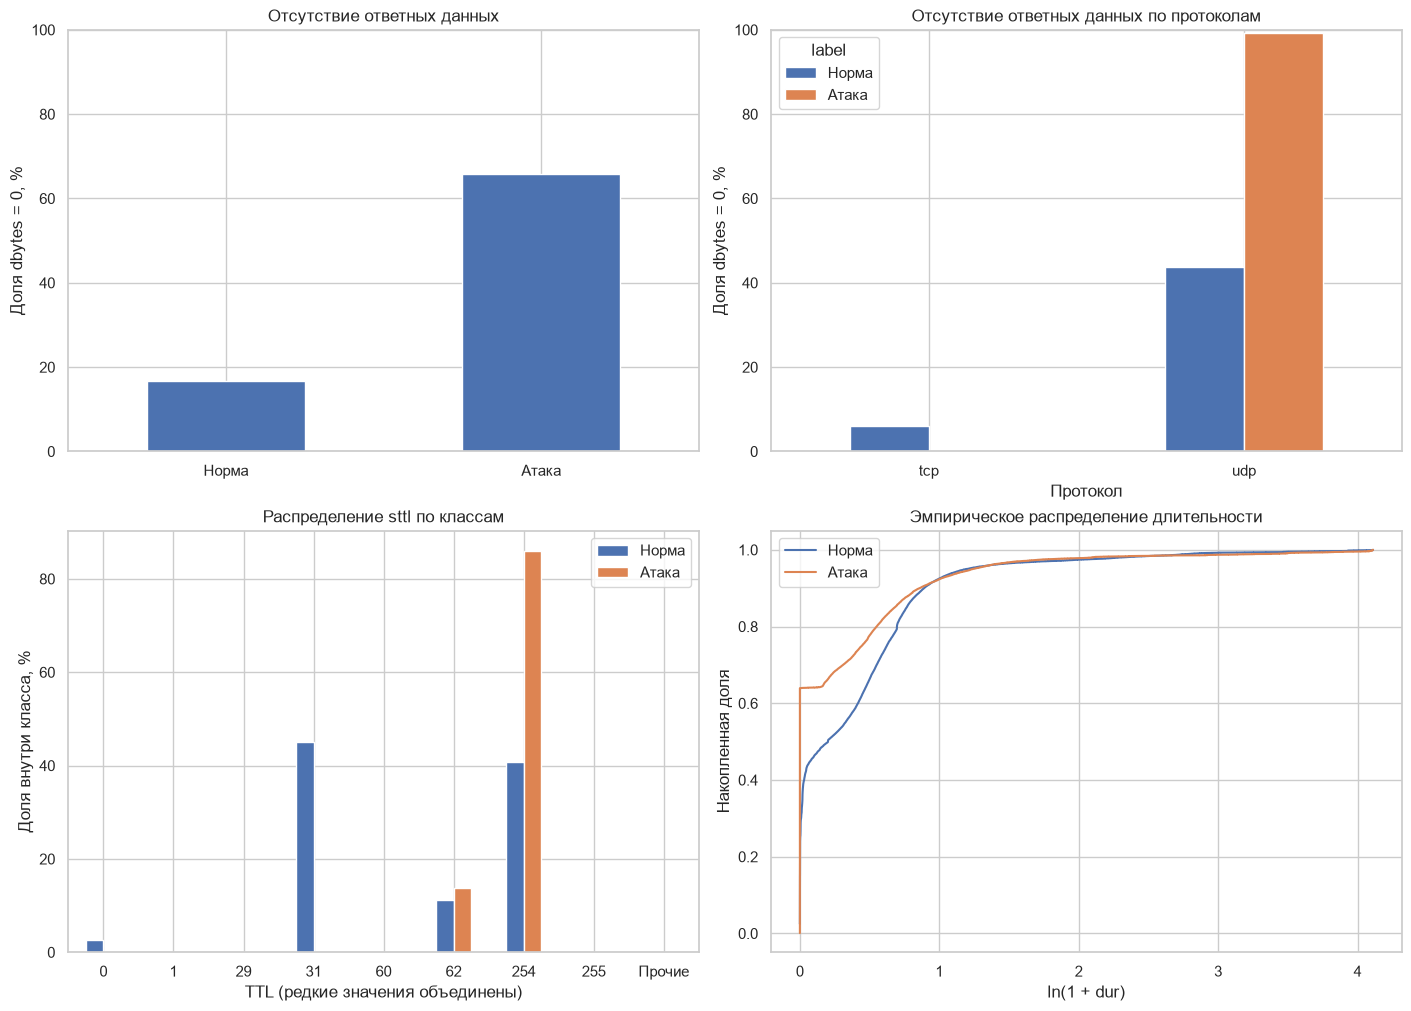

In [13]:
# Наглядное сопоставление четырёх статистических закономерностей.
fig, axs = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

traffic_zero_rates["mean"].mul(100).plot.bar(ax=axs[0, 0], rot=0)
axs[0, 0].set(title="Отсутствие ответных данных", ylabel="Доля dbytes = 0, %", xlabel="")
axs[0, 0].set_ylim(0, 100)

traffic_by_protocol_plot = traffic_tcp_udp["mean"].unstack("label").rename(columns={0:"Норма", 1:"Атака"}).mul(100)
traffic_by_protocol_plot.plot.bar(ax=axs[0, 1], rot=0)
axs[0, 1].set(title="Отсутствие ответных данных по протоколам", ylabel="Доля dbytes = 0, %", xlabel="Протокол")
axs[0, 1].set_ylim(0, 100)

traffic_ttl_norm = traffic_ttl_table.div(traffic_ttl_table.sum(axis=0), axis=1).mul(100)
traffic_ttl_norm.plot.bar(ax=axs[1, 0], rot=0)
axs[1, 0].set(title="Распределение sttl по классам", ylabel="Доля внутри класса, %", xlabel="TTL (редкие значения объединены)")

# Эмпирическая функция распределения без промежуточного сглаживания.
for traffic_label, traffic_class in [(0, "Норма"), (1, "Атака")]:
    traffic_values = np.sort(test.loc[test["label"] == traffic_label, "dur"].to_numpy(dtype=float))
    traffic_unique, traffic_counts = np.unique(traffic_values, return_counts=True)
    axs[1, 1].step(np.log1p(traffic_unique), np.cumsum(traffic_counts) / len(traffic_values),
                   where="post", label=traffic_class)
axs[1, 1].set(title="Эмпирическое распределение длительности", xlabel="ln(1 + dur)", ylabel="Накопленная доля")
axs[1, 1].legend()
plt.savefig(OUT / "four_traffic_hypotheses.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Корреляционный анализ

Вычисляются корреляции Пирсона и Спирмена между числовыми признаками и связи характеристик с меткой атаки.

In [14]:
exclude = {"id", "label", "attack_cat"}
num_cols = [x for x in train.select_dtypes(include="number").columns if x not in exclude]
cat_cols = [x for x in train.select_dtypes(include=["object", "string"]).columns if x not in exclude]
print("Числовых признаков:", len(num_cols), "Категориальные:", cat_cols)

Числовых признаков: 39 Категориальные: ['proto', 'service', 'state']


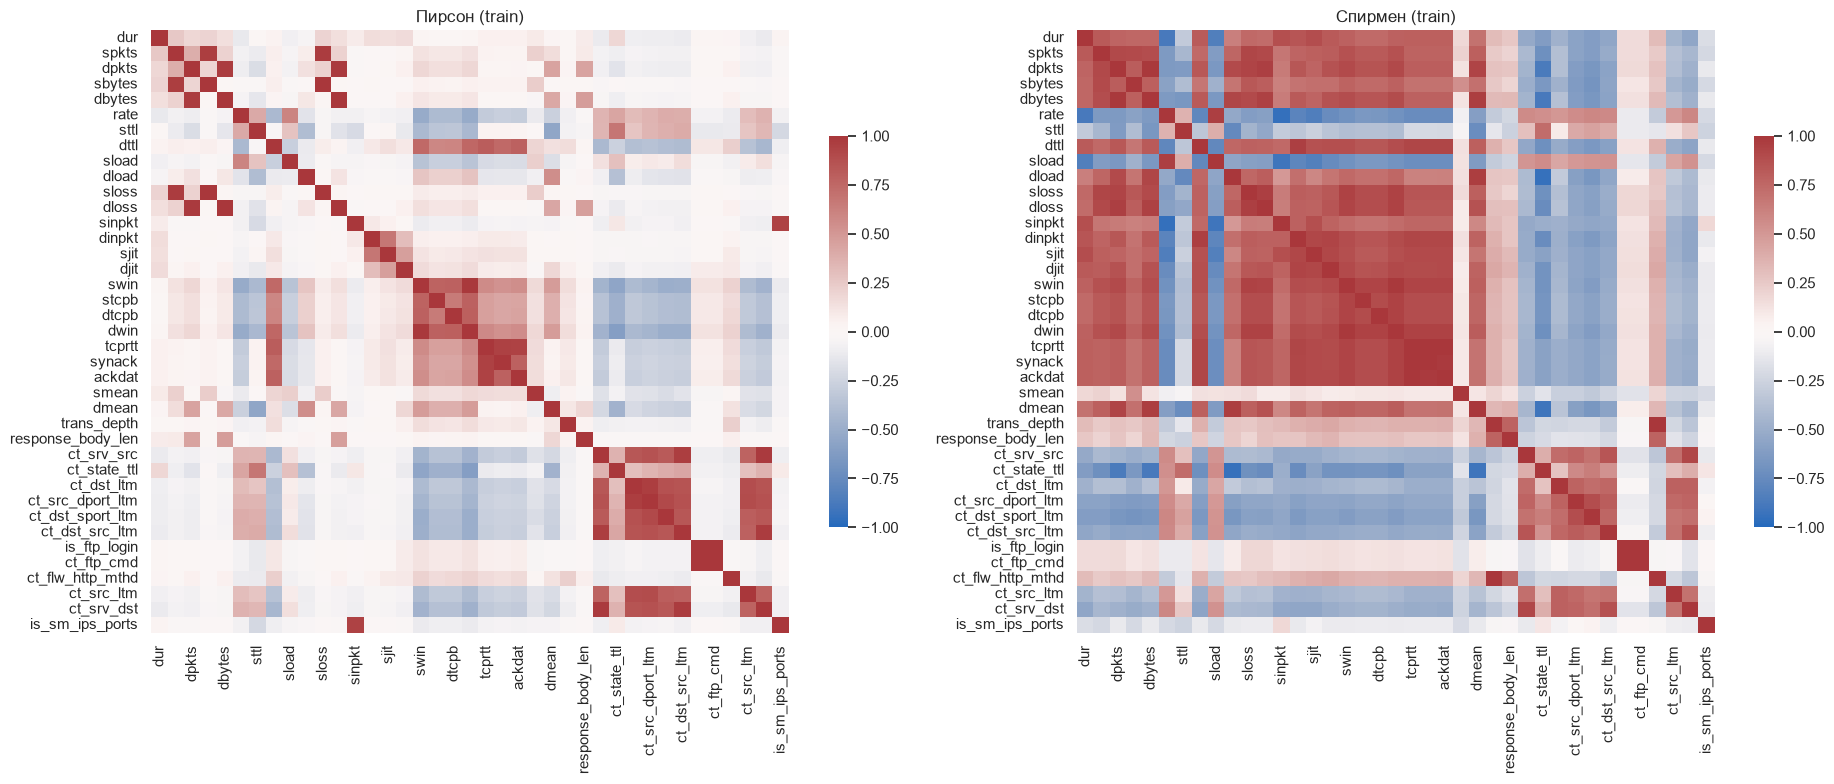

In [15]:
# Корреляции между числовыми признаками, в том числе бинарными индикаторами
pearson = train[num_cols].corr(method="pearson")
spearman = train[num_cols].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(19, 8))
sns.heatmap(pearson, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax[0], cbar_kws={"shrink": .65})
sns.heatmap(spearman, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax[1], cbar_kws={"shrink": .65})
ax[0].set_title("Пирсон (train)")
ax[1].set_title("Спирмен (train)")
plt.tight_layout()
plt.savefig(OUT / "correlation_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()


In [16]:
# Список сильнейших корреляций без самокорреляций и повторения (a,b)/(b,a)
pairs = []
for i, a in enumerate(num_cols):
    for b in num_cols[i + 1:]:
        p, s = pearson.loc[a, b], spearman.loc[a, b]
        pairs.append((a, b, p, s))
pair_table = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson_r", "spearman_rho"])
pair_table["max_abs_corr"] = pair_table[["pearson_r", "spearman_rho"]].abs().max(axis=1)
pair_table = pair_table.sort_values("max_abs_corr", ascending=False)
display(pair_table.head(20).round(3))
# Прямое отношение числового признака к бинарной метке: Пирсон = point-biserial correlation
label_corr = pd.DataFrame({
    "pearson_with_label": train[num_cols].corrwith(train["label"]),
    "spearman_with_label": train[num_cols].corrwith(train["label"], method="spearman")
}).sort_values("pearson_with_label", key=lambda s: s.abs(), ascending=False)
display(label_corr.head(20).round(3))


,feature_1,feature_2,pearson_r,spearman_rho,max_abs_corr
726,is_ftp_login,ct_ftp_cmd,1.000,1.000,1.000
659,trans_depth,ct_flw_http_mthd,0.226,1.000,1.000
570,tcprtt,synack,0.949,0.997,0.997
152,dbytes,dloss,0.997,0.947,0.997
117,sbytes,sloss,0.996,0.832,0.996
571,tcprtt,ackdat,0.942,0.994,0.994
490,swin,dwin,0.990,0.990,0.990
76,dpkts,dbytes,0.972,0.990,0.990
588,synack,ackdat,0.789,0.984,0.984
684,ct_srv_src,ct_srv_dst,0.980,0.920,0.980


,pearson_with_label,spearman_with_label
sttl,0.693,0.732
ct_state_ttl,0.578,0.644
dload,-0.394,-0.626
ct_dst_sport_ltm,0.357,0.430
dmean,-0.342,-0.546
rate,0.338,0.287
swin,-0.334,-0.334
dwin,-0.320,-0.320
ct_src_dport_ltm,0.306,0.326
ct_dst_src_ltm,0.304,0.220


### 4.1. Отбор информативных признаков

Формируется набор признаков с одномерной ROC-AUC не ниже 0,80 и значимостью по Холму; анализируются корреляции внутри набора.

In [17]:
# Выбор наиболее информативных признаков фиксируем ДО обращения к official test.
MIN_SELECTED_AUC = 0.80
selected_features = results.loc[
    (results["auc_validation"] >= MIN_SELECTED_AUC) & results["reject_Holm"],
    "feature"
].tolist()
assert len(selected_features) >= 2, "Правило отбора дало менее двух признаков — проверьте расчёты."
selected_numeric = [f for f in selected_features if f in numeric_features]
selected_categorical = [f for f in selected_features if f in categorical_features]
print(f"Выбрано {len(selected_features)} признаков из {len(input_features)} (AUC >= {MIN_SELECTED_AUC}; Holm p<0.05):")
print(", ".join(selected_features))
display(results.set_index("feature").loc[selected_features, ["rank", "auc_validation", "p_Holm"]].round(4))
if len(selected_numeric) >= 2:
    selected_corr = pearson.loc[selected_numeric, selected_numeric]
    upper_corr = selected_corr.where(np.triu(np.ones(selected_corr.shape), k=1).astype(bool))
    strong_pairs = upper_corr.stack().rename("pearson_r").reset_index()
    strong_pairs.columns = ["feature_1", "feature_2", "pearson_r"]
    strong_pairs["abs_r"] = strong_pairs.pearson_r.abs()
    strong_pairs = strong_pairs.sort_values("abs_r", ascending=False)
    print("Наиболее сильные взаимные корреляции среди выбранных числовых признаков:")
    display(strong_pairs.head(15).round(3))
else:
    strong_pairs = pd.DataFrame(columns=["feature_1", "feature_2", "pearson_r", "abs_r"])


Выбрано 14 признаков из 42 (AUC >= 0.8; Holm p<0.05):
ct_state_ttl, dttl, sttl, dinpkt, dload, dur, dpkts, smean, dmean, sbytes, sload, dbytes, state, sinpkt


,rank,auc_validation,p_Holm
feature,,,
ct_state_ttl,1,0.9012,0.042
dttl,2,0.8895,0.042
sttl,3,0.8867,0.042
dinpkt,4,0.8762,0.042
dload,5,0.8709,0.042
dur,6,0.8547,0.042
dpkts,7,0.8539,0.042
smean,8,0.8420,0.042
dmean,9,0.8416,0.042


Наиболее сильные взаимные корреляции среди выбранных числовых признаков:


,feature_1,feature_2,pearson_r,abs_r
89,dpkts,dbytes,0.972,0.972
2,ct_state_ttl,sttl,0.672,0.672
60,dload,dmean,0.551,0.551
34,sttl,dmean,-0.550,0.550
8,ct_state_ttl,dmean,-0.465,0.465
86,dpkts,dmean,0.441,0.441
115,dmean,dbytes,0.420,0.420
30,sttl,dload,-0.397,0.397
4,ct_state_ttl,dload,-0.373,0.373
10,ct_state_ttl,sload,0.290,0.290


### 4.2. Корреляционная фильтрация

Числовые признаки рассматриваются по убыванию одномерной ROC-AUC; исключаются признаки, имеющие корреляцию Пирсона или Спирмена по модулю не ниже 0,95 с уже сохранёнными. Категориальные признаки сохраняются.

In [18]:
# Третий набор: исключаем почти дублирующие числовые признаки.
# Все решения фиксируются по train/validation, ДО просмотра official test.
MAX_ABS_CORRELATION = 0.95
correlation_pruned_features = []
correlation_removed_rows = []

# selected_features уже отсортированы по убыванию одномерной ROC-AUC.
for feature in selected_features:
    if feature in categorical_features:
        correlation_pruned_features.append(feature)
        continue

    reasons = []
    for kept in correlation_pruned_features:
        if kept not in numeric_features:
            continue
        r = float(pearson.loc[feature, kept])
        rho = float(spearman.loc[feature, kept])
        if max(abs(r), abs(rho)) >= MAX_ABS_CORRELATION:
            reasons.append({
                "removed_feature": feature,
                "kept_instead": kept,
                "auc_removed": float(results.set_index("feature").loc[feature, "auc_validation"]),
                "auc_kept": float(results.set_index("feature").loc[kept, "auc_validation"]),
                "pearson_r": r,
                "spearman_rho": rho,
                "max_abs_correlation": max(abs(r), abs(rho)),
            })

    if reasons:
        # Для прозрачности указываем наиболее сильно связанную сохранённую характеристику.
        correlation_removed_rows.append(max(reasons, key=lambda x: x["max_abs_correlation"]))
    else:
        correlation_pruned_features.append(feature)

correlation_removed = pd.DataFrame(correlation_removed_rows, columns=[
    "removed_feature", "kept_instead", "auc_removed", "auc_kept",
    "pearson_r", "spearman_rho", "max_abs_correlation"
])
pruned_numeric = [f for f in correlation_pruned_features if f in numeric_features]
pruned_categorical = [f for f in correlation_pruned_features if f in categorical_features]
assert len(correlation_pruned_features) >= 2
assert set(correlation_pruned_features).issubset(set(selected_features))
assert len(correlation_pruned_features) + len(correlation_removed) == len(selected_features)

# Контроль: среди оставшихся числовых пар нет корреляций >= порога.
for i, f in enumerate(pruned_numeric):
    for g in pruned_numeric[i + 1:]:
        assert max(abs(pearson.loc[f, g]), abs(spearman.loc[f, g])) < MAX_ABS_CORRELATION

print(f"Порог максимальной |корреляции|: {MAX_ABS_CORRELATION:.2f} (Пирсон ИЛИ Спирмен)")
print(f"Первоначально информативных признаков: {len(selected_features)}")
print(f"После корреляционной фильтрации: {len(correlation_pruned_features)}")
print("Оставшиеся признаки:", ", ".join(correlation_pruned_features))
print("Исключённые признаки и их более информативные аналоги:")
display(correlation_removed.round(4))


Порог максимальной |корреляции|: 0.95 (Пирсон ИЛИ Спирмен)
Первоначально информативных признаков: 14
После корреляционной фильтрации: 11
Оставшиеся признаки: ct_state_ttl, dttl, sttl, dload, dur, dpkts, smean, sbytes, sload, state, sinpkt
Исключённые признаки и их более информативные аналоги:


,removed_feature,kept_instead,auc_removed,auc_kept,pearson_r,spearman_rho,max_abs_correlation
0,dinpkt,dttl,0.8762,0.8895,0.0980,0.9596,0.9596
1,dmean,dload,0.8416,0.8709,0.5506,0.9629,0.9629
2,dbytes,dpkts,0.8207,0.8539,0.9719,0.9899,0.9899


## 5. Классификация

Сравниваются три логистические регрессии: на всех признаках, на информативных признаках и после корреляционной фильтрации.

### 5.1. Обучение и метрики

Единая предобработка и параметры обучения. Качество оценивается на официальной тестовой выборке; для дискретных решений используется порог 0,5.

In [19]:
# Только один раз готовим исходные выборки и три набора признаков.
X_train = train.drop(columns=["id", "label", "attack_cat"])
X_test = test.drop(columns=["id", "label", "attack_cat"])
y_train = train["label"]
y_test = test["label"]

constant_cols = [c for c in X_train.columns if X_train[c].nunique(dropna=False) <= 1]
X_train = X_train.drop(columns=constant_cols)
X_test = X_test.drop(columns=constant_cols)

feature_sets = {
    "Все признаки": X_train.columns.tolist(),
    "Информативные": [c for c in selected_features if c in X_train.columns],
    "Без сильных корреляций": [c for c in correlation_pruned_features if c in X_train.columns],
}
assert len(feature_sets) == 3
assert len(feature_sets["Информативные"]) == len(selected_features)
assert len(feature_sets["Без сильных корреляций"]) == len(correlation_pruned_features)
assert set(feature_sets["Без сильных корреляций"]).issubset(feature_sets["Информативные"])

print("Константные исходные признаки (исключены только по train):", constant_cols)
print("Количество исходных признаков:", {k: len(v) for k, v in feature_sets.items()})
print(f"Train: {len(X_train):,} соединений; test: {len(X_test):,}; доля атак test: {y_test.mean():.2%}")

Константные исходные признаки (исключены только по train): []
Количество исходных признаков: {'Все признаки': 42, 'Информативные': 14, 'Без сильных корреляций': 11}
Train: 175,341 соединений; test: 82,332; доля атак test: 55.06%


In [20]:
def make_logistic_pipeline(features):
    numeric = [f for f in features if f in numeric_features]
    categorical = [f for f in features if f in categorical_features]
    transformer = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=100,
                sparse_output=False,
                dtype=np.float32,
            )),
        ]), categorical),
    ], sparse_threshold=0)
    return Pipeline([
        ("preprocessor", transformer),
        ("classifier", LogisticRegression(
            max_iter=1000, solver="lbfgs", random_state=RANDOM_STATE,
        )),
    ])

# Все три модели обучаются по одной процедуре и оцениваются на одном test.
comparison_models = {}
model_probabilities = {}
model_predictions = {}
model_confusions = {}
model_rows = []

for name, features in feature_sets.items():
    model = make_logistic_pipeline(features)
    model.fit(X_train[features], y_train)
    probability = model.predict_proba(X_test[features])[:, list(model.classes_).index(1)]
    prediction = model.predict(X_test[features])
    cm = confusion_matrix(y_test, prediction, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    comparison_models[name] = model
    model_probabilities[name] = probability
    model_predictions[name] = prediction
    model_confusions[name] = cm
    model_rows.append({
        "model": name,
        "n_source_features": len(features),
        "n_transformed_features": len(model.named_steps["preprocessor"].get_feature_names_out()),
        "roc_auc": roc_auc_score(y_test, probability),
        "average_precision": average_precision_score(y_test, probability),
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "false_positive_rate": fp / (fp + tn),
    })

model_comparison = pd.DataFrame(model_rows).set_index("model")
comparison_confusion = pd.DataFrame({
    name: dict(zip(["TN", "FP", "FN", "TP"], cm.ravel()))
    for name, cm in model_confusions.items()
}).T
comparison_confusion.index.name = "model"

print("Сравнение трёх логистических регрессий на официальной test (порог 0,5):")
display(model_comparison.round(4))
print("Матрицы ошибок, строками (одинаковые наблюдения test):")
display(comparison_confusion)

# Константная модель нужна лишь как минимальный контрольный ориентир.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(np.zeros((len(y_train), 1)), y_train)
dummy_pred = dummy_model.predict(np.zeros((len(y_test), 1)))
dummy_prob = dummy_model.predict_proba(np.zeros((len(y_test), 1)))[:, list(dummy_model.classes_).index(1)]
dummy_reference = pd.DataFrame([{
    "roc_auc": roc_auc_score(y_test, dummy_prob),
    "f1": f1_score(y_test, dummy_pred, zero_division=0),
    "accuracy": accuracy_score(y_test, dummy_pred),
}], index=["Dummy (most frequent)"])
print("Базовый ориентир (не участвует в сравнительных графиках):")
display(dummy_reference.round(4))

Сравнение трёх логистических регрессий на официальной test (порог 0,5):


,n_source_features,n_transformed_features,roc_auc,average_precision,accuracy,precision,recall,f1,false_positive_rate
model,,,,,,,,,
Все признаки,42,156,0.9553,0.9659,0.8089,0.7527,0.9723,0.8485,0.3914
Информативные,14,18,0.8960,0.8799,0.8053,0.7412,0.9931,0.8489,0.4248
Без сильных корреляций,11,15,0.8779,0.8564,0.8049,0.7410,0.9925,0.8486,0.4249


Матрицы ошибок, строками (одинаковые наблюдения test):


,TN,FP,FN,TP
model,,,,
Все признаки,22518,14482,1254,44078
Информативные,21284,15716,313,45019
Без сильных корреляций,21277,15723,338,44994


Базовый ориентир (не участвует в сравнительных графиках):


,roc_auc,f1,accuracy
Dummy (most frequent),0.5,0.7102,0.5506


### 5.2. Сравнительные графики

Общие ROC- и Precision–Recall-кривые, матрицы ошибок и сравнение метрик трёх классификаторов.

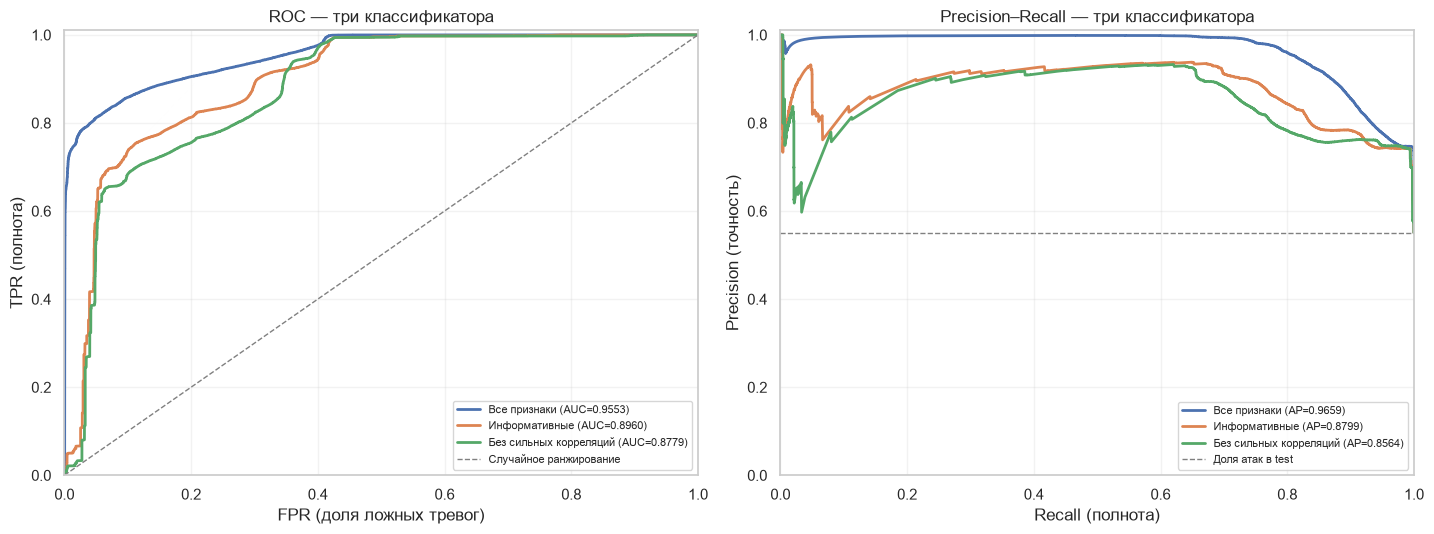

In [21]:
# ROC и Precision–Recall: все три модели на двух общих графиках.
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))
for name, scores in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={roc_auc_score(y_test, scores):.4f})")
    axes[1].plot(recall, precision, linewidth=2, label=f"{name} (AP={average_precision_score(y_test, scores):.4f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="Случайное ранжирование")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", linewidth=1, label="Доля атак в test")
axes[0].set(xlabel="FPR (доля ложных тревог)", ylabel="TPR (полнота)", title="ROC — три классификатора", xlim=(0, 1), ylim=(0, 1.01))
axes[1].set(xlabel="Recall (полнота)", ylabel="Precision (точность)", title="Precision–Recall — три классификатора", xlim=(0, 1), ylim=(0, 1.01))
for ax in axes:
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "three_model_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

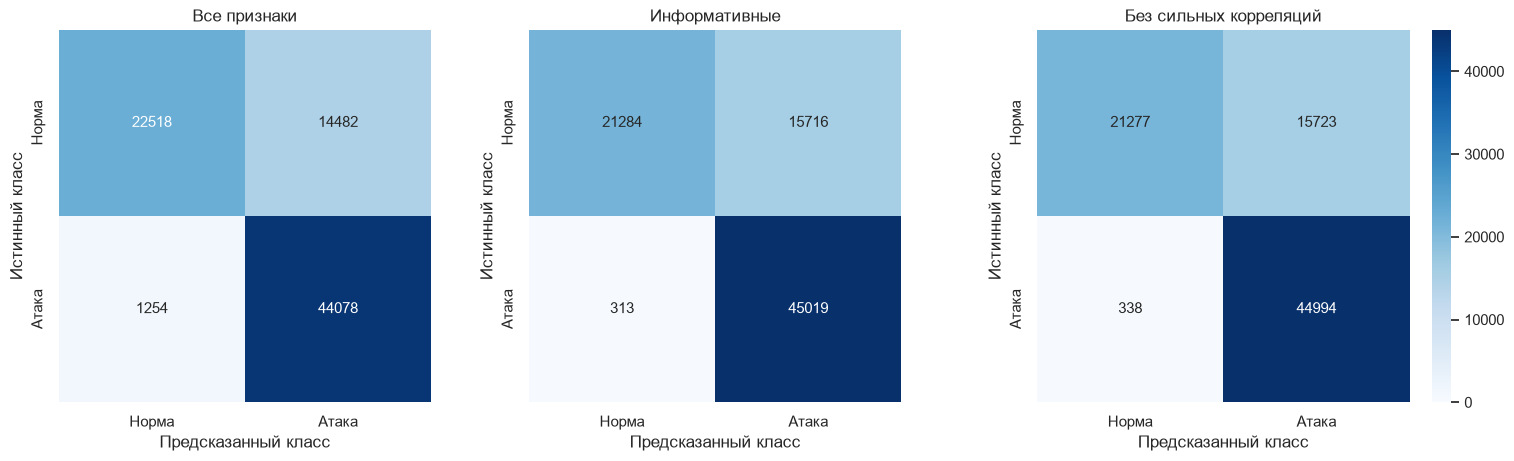

In [22]:
# Три матрицы ошибок рядом, с одинаковым цветовым масштабом и числом наблюдений.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
max_count = max(int(cm.max()) for cm in model_confusions.values())
for i, (ax, (name, cm)) in enumerate(zip(axes, model_confusions.items())):
    sns.heatmap(
        cm, ax=ax, annot=True, fmt="d", cmap="Blues",
        vmin=0, vmax=max_count, square=True,
        xticklabels=["Норма", "Атака"], yticklabels=["Норма", "Атака"],
        cbar=(i == 2), annot_kws={"fontsize": 11},
    )
    ax.set_title(name)
    ax.set(xlabel="Предсказанный класс", ylabel="Истинный класс")
plt.savefig(OUT / "three_model_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

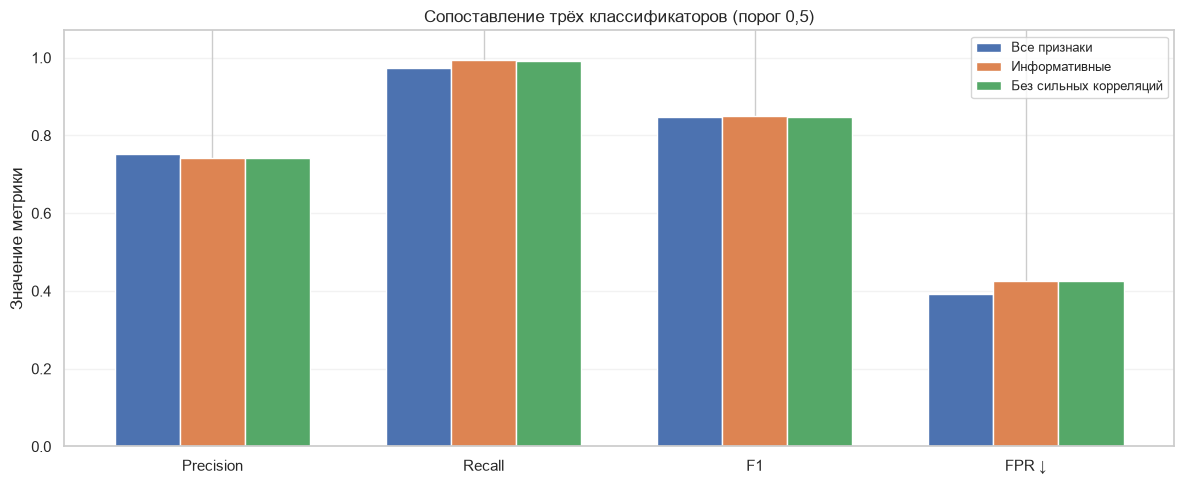

In [23]:
# Единый график классификационных метрик при пороге 0,5.
# FPR включён для сопоставления ложных тревог (для него МЕНЬШЕ — лучше).
metrics_to_plot = ["precision", "recall", "f1", "false_positive_rate"]
metric_labels = ["Precision", "Recall", "F1", "FPR ↓"]
values = model_comparison[metrics_to_plot]
x_positions = np.arange(len(metrics_to_plot))
width = 0.24
fig, ax = plt.subplots(figsize=(12, 5))
for i, (model_name, row) in enumerate(values.iterrows()):
    ax.bar(x_positions + (i - 1) * width, row.to_numpy(), width, label=model_name)
ax.set_xticks(x_positions, metric_labels)
ax.set(ylabel="Значение метрики", ylim=(0, 1.07), title="Сопоставление трёх классификаторов (порог 0,5)")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "three_model_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Экспорт результатов

Сохранение расчётных таблиц и графиков в папку `unsw_results`. Результаты дополнительных статистических гипотез сохраняются в разделе 3.

In [ ]:
tables = {
    "feature_informativeness.csv": feature_informativeness,
    "feature_bin_profiles.csv": feature_bin_profiles,
    "categorical_attack_rates.csv": categorical_attack_rates,
    "quality.csv": quality,
    "class_balance.csv": class_table,
    "attack_categories.csv": attack_table,
    "descriptive_all.csv": stats_all,
    "descriptive_by_class.csv": stats_by_class,
    "class_comparison.csv": comparison,
    "outlier_summary.csv": outlier_table,
    "hypothesis_tests_all_42_auc.csv": results,
    "pearson.csv": pearson,
    "spearman.csv": spearman,
    "correlation_pairs.csv": pair_table,
    "selected_features_correlations.csv": strong_pairs,
    "correlation_pruning_removed.csv": correlation_removed,
    "correlation_pruning_kept.csv": results.set_index("feature").loc[correlation_pruned_features].reset_index(),
    "selected_features.csv": results.set_index("feature").loc[selected_features].reset_index(),
    "label_correlations.csv": label_corr,
    "three_model_comparison.csv": model_comparison,
    "three_model_confusion.csv": comparison_confusion,
    "dummy_reference.csv": dummy_reference,
}
for filename, df in tables.items():
    df.to_csv(OUT / filename, encoding="utf-8-sig", index=True)
print(f"Сохранено {len(tables)} таблиц в {OUT.resolve()}")